# Task 1 — đọc báo cáo public test

Notebook này chỉ đọc output của [`03_task1_public_test.ipynb`](03_task1_public_test.ipynb). Không gọi API, không sửa `predictions.json`.

Public test không có nhãn nên không có QWK/MAE. Các hình dưới đây trả lời: lượt chạy đã đủ bài chưa, điểm nằm ở đâu, sáu chiều rubric lệch nhau thế nào, model gán trạng thái câu ra sao, và token tốn bao nhiêu.

Đọc từ trên xuống:

1. Tóm tắt lượt chạy
2. Điểm tổng
3. Sáu chiều rubric
4. Trạng thái từng câu và rule
5. Token
6. Bài nên mở checkpoint

`SAVE_REPORT = True` ghi PNG, CSV và `summary.md` vào `<thư mục run>/report/` trên Drive. `predictions.json` giữ nguyên để nộp.

In [1]:
from pathlib import Path
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    _default_root = "/content/drive/MyDrive/LLM/Final Project/data/outputs/task1"
else:
    _default_root = "data/outputs/task1"

OUTPUT_ROOT = Path(os.environ.get("TASK1_OUTPUT_ROOT", _default_root))
# Gán đường dẫn thư mục chứa progress.json nếu không muốn lấy lượt mới nhất đã đủ bài.
RUN_DIR = os.environ.get("TASK1_PUBLIC_RUN_DIR") or None
SAVE_REPORT = True

EXAM_ORDER = [
    "Class01-Test1", "Class01-Test2", "Class02-Test1",
    "Class03-Midterm-1", "Class03-Midterm-2", "Class03-Final-1",
]
DIMENSIONS = ["compilable", "io_format", "logic", "edge_case", "complexity", "code_quality"]
DIM_MAX = {"compilable": 1, "io_format": 1, "logic": 4, "edge_case": 2, "complexity": 1, "code_quality": 1}
STATUSES = ["correct", "partial", "wrong", "runtime_error", "not_attempted"]
STATUS_COLOR = {
    "correct": "#2e7d32",
    "partial": "#f9a825",
    "wrong": "#c62828",
    "runtime_error": "#ef6c00",
    "not_attempted": "#90a4ae",
}

def exam_of(sample_id: str) -> str:
    text = str(sample_id).split("[", 1)[0]
    return text.rsplit("-S", 1)[0] if "-S" in text else text

def exam_rank(exam: str) -> int:
    return EXAM_ORDER.index(exam) if exam in EXAM_ORDER else len(EXAM_ORDER)

def pid_rank(pid: str):
    digits = "".join(ch for ch in str(pid) if ch.isdigit())
    return (int(digits) if digits else 999, str(pid))

def show(obj):
    try:
        from IPython.display import display
        display(obj)
    except Exception:
        print(obj)

def finish(fig, name: str):
    fig.tight_layout()
    if SAVE_REPORT:
        REPORT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(REPORT_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

if RUN_DIR is None:
    found = sorted(OUTPUT_ROOT.glob("public/**/progress.json"), key=lambda p: p.stat().st_mtime, reverse=True)
    if not found:
        raise FileNotFoundError(
            f"Không thấy progress.json trong {OUTPUT_ROOT}. Chạy notebook 03 trước, hoặc gán RUN_DIR.")
    def _complete(path: Path) -> bool:
        report = json.loads(path.read_text(encoding="utf-8"))
        return report.get("completed") == report.get("expected") and report.get("expected")
    done = [path for path in found if _complete(path)]
    RUN_DIR = (done or found)[0].parent
else:
    RUN_DIR = Path(RUN_DIR)

if not (RUN_DIR / "progress.json").is_file():
    raise FileNotFoundError(f"Không thấy progress.json trong {RUN_DIR}")

REPORT_DIR = RUN_DIR / "report"
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#fafafa",
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.axisbelow": True,
    "font.size": 11,
})
print("Run:", RUN_DIR)

Mounted at /content/drive
Run: /content/drive/MyDrive/LLM/Final Project/data/outputs/task1/public/gemini/gemini-3.5-flash-lite/e2_zero_shot_structured__gemini__gemini-3.5-flash-lite/891019e6d679


In [2]:
progress = json.loads((RUN_DIR / "progress.json").read_text(encoding="utf-8"))

pred_path = RUN_DIR / "predictions.json"
if pred_path.is_file():
    predictions = json.loads(pred_path.read_text(encoding="utf-8"))
    pred_source = pred_path.name
else:
    predictions = []
    ckpt_dir = RUN_DIR / "checkpoints"
    for ck in sorted(ckpt_dir.glob("*.json")) if ckpt_dir.is_dir() else []:
        saved = json.loads(ck.read_text(encoding="utf-8"))
        if isinstance(saved.get("submission"), dict):
            predictions.append(saved["submission"])
    pred_source = "checkpoints (chưa có predictions.json)"

score_rows = []
for item in predictions:
    rubric = (item.get("output") or {}).get("rubric") or {}
    if any(d not in rubric for d in DIMENSIONS):
        continue
    total = item["output"].get("total_score")
    row = {"sample_id": item["sample_id"], "exam": exam_of(item["sample_id"]), "total": float(total)}
    row.update({d: float(rubric[d]) for d in DIMENSIONS})
    row["rubric_sum"] = sum(row[d] for d in DIMENSIONS)
    row["sum_mismatch"] = abs(row["rubric_sum"] - row["total"]) > 0.001
    score_rows.append(row)
scores = pd.DataFrame(score_rows)
if scores.empty:
    raise RuntimeError(f"{RUN_DIR} chưa có điểm hợp lệ trong predictions.json hoặc checkpoints.")
scores["_ord"] = scores["exam"].map(exam_rank)
scores = scores.sort_values(["_ord", "sample_id"]).drop(columns="_ord").reset_index(drop=True)

problem_rows, trace_rows = [], []
ckpt_dir = RUN_DIR / "checkpoints"
if ckpt_dir.is_dir():
    for ck in sorted(ckpt_dir.glob("*.json")):
        saved = json.loads(ck.read_text(encoding="utf-8"))
        sid = ck.stem
        exam = exam_of(sid)
        for pid, status in (saved.get("problems") or {}).items():
            problem_rows.append({
                "sample_id": sid, "exam": exam, "pid": str(pid),
                "status": status or "unknown",
            })
        for line in saved.get("rule_trace") or []:
            text = str(line)
            trace_rows.append({
                "sample_id": sid, "exam": exam, "trace": text,
                "kind": text.split(":", 1)[0],
            })
problems = pd.DataFrame(problem_rows)
traces = pd.DataFrame(trace_rows)

usage_rows = []
usage_path = RUN_DIR / "usage.jsonl"
if usage_path.is_file():
    for line in usage_path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            usage_rows.append(json.loads(line))
usage = pd.DataFrame(usage_rows)
if not usage.empty and "sample_id" in usage.columns:
    usage["exam"] = usage["sample_id"].map(exam_of)

print(f"Điểm: {len(scores)} bài, nguồn {pred_source}")
print(f"Trạng thái câu: {len(problems)} dòng | rule: {len(traces)} dòng | usage: {len(usage)} sự kiện")

Điểm: 360 bài, nguồn predictions.json
Trạng thái câu: 777 dòng | rule: 212 dòng | usage: 361 sự kiện


## 1. Tóm tắt lượt chạy

Đọc bảng này trước. `completed/expected` phải là 360/360 thì `predictions.json` mới là file nộp. `usage_this_run` là lần chạy cell đầy đủ vừa xong; `usage_total` cộng cả các lần trước còn trong `usage.jsonl` (ví dụ smoke 8 bài).

In [3]:
usage_total = progress.get("usage_total") or {}
usage_run = progress.get("usage_this_run") or {}
cost = usage_total.get("cost_usd")
overview = pd.DataFrame([
    ("Provider / model", f"{progress.get('provider')} / {progress.get('model')}"),
    ("Experiment", progress.get("experiment")),
    ("Release", progress.get("release_key")),
    ("Commit", progress.get("source_commit")),
    ("Tiến độ", f"{progress.get('completed')}/{progress.get('expected')}"),
    ("Thiếu bài", len(progress.get("missing_ids") or [])),
    ("Lỗi", len(progress.get("errors") or [])),
    ("Dừng giữa chừng", progress.get("stopped") or "không"),
    ("File nộp", progress.get("submission_path") or "chưa đủ bài hợp lệ"),
    ("Request lần này", usage_run.get("requests")),
    ("Token vào / ra (lần này)", f"{usage_run.get('prompt_tokens')} / {usage_run.get('output_tokens')}"),
    ("Token vào / ra (cả usage.jsonl)", f"{usage_total.get('input_tokens')} / {usage_total.get('output_tokens')}"),
    ("Chi phí USD", "không có đơn giá" if cost is None else f"{cost:.4f}"),
], columns=["Mục", "Giá trị"])
show(overview)

if progress.get("errors"):
    print("Lỗi từng bài:")
    show(pd.DataFrame(progress["errors"]))
if progress.get("missing_ids"):
    missing = progress["missing_ids"]
    print(f"Thiếu {len(missing)} bài, ví dụ: {missing[:8]}")
if progress.get("completed") != progress.get("expected"):
    print("Lượt này chưa đủ bài. Biểu đồ bên dưới chỉ phủ các checkpoint đã có, chưa phải file nộp.")

,Mục,Giá trị
0,Provider / model,gemini / gemini-3.5-flash-lite
1,Experiment,e2_zero_shot_structured__gemini__gemini-3.5-fl...
2,Release,891019e6d679
3,Commit,4e3fbdaf4b699b86464aa4be3997cd7d7571a5a0
4,Tiến độ,360/360
5,Thiếu bài,0
6,Lỗi,0
7,Dừng giữa chừng,không
8,File nộp,/content/drive/MyDrive/LLM/Final Project/data/...
9,Request lần này,353


## 2. Điểm tổng

Histogram cho biết điểm dồn về đâu. Chấm từng bài cho thấy từng đề có trải đều hay tụ một cụm; vạch đỏ là trung bình đề đó. Bảng phía dưới là số liệu để đọc cùng hình.

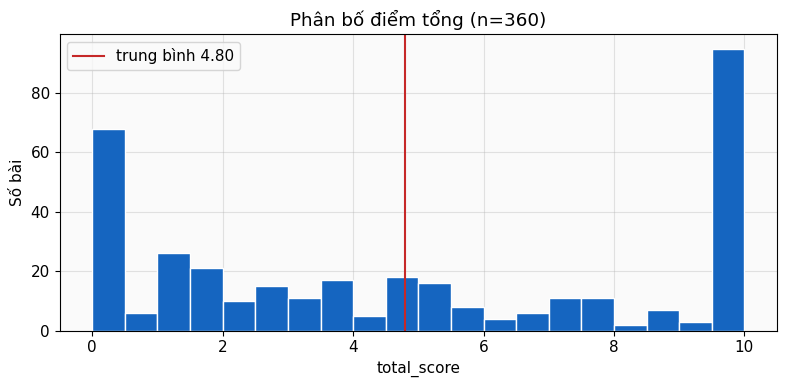

,khoảng điểm,số bài
0,0–1,74
1,1–2,47
2,2–3,25
3,3–4,28
4,4–5,23
5,5–6,24
6,6–7,10
7,7–8,22
8,8–9,9
9,9–10,98


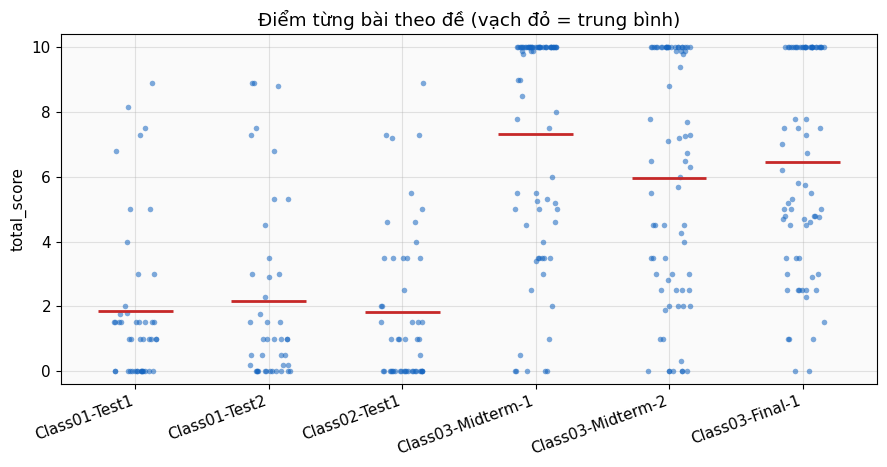

,n,mean,median,min,max,n_zero,n_full,compilable,io_format,logic,edge_case,complexity,code_quality
exam,,,,,,,,,,,,,
Class01-Test1,46,1.86,1.0,0.0,8.9,16,0,0.65,0.31,0.40,0.17,0.16,0.16
Class01-Test2,43,2.16,1.0,0.0,8.9,12,0,0.56,0.29,0.56,0.21,0.25,0.29
Class02-Test1,50,1.82,1.0,0.0,8.9,22,0,0.54,0.27,0.44,0.14,0.23,0.20
Class03-Midterm-1,75,7.33,9.9,0.0,10.0,5,37,0.92,0.80,2.63,1.33,0.90,0.75
Class03-Midterm-2,73,5.97,6.5,0.0,10.0,7,22,0.89,0.64,2.10,0.95,0.75,0.65
Class03-Final-1,73,6.46,6.2,0.0,10.0,2,28,0.97,0.75,2.09,1.01,0.90,0.74


In [4]:
exams = sorted(scores["exam"].unique(), key=exam_rank)
mean_total = scores["total"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores["total"], bins=[i * 0.5 for i in range(21)], color="#1565c0", edgecolor="white")
ax.axvline(mean_total, color="#c62828", linewidth=1.5, label=f"trung bình {mean_total:.2f}")
ax.set_xlabel("total_score")
ax.set_ylabel("Số bài")
ax.set_title(f"Phân bố điểm tổng (n={len(scores)})")
ax.legend()
finish(fig, "01_total_hist")

# a–b = điểm từ a đến dưới b; riêng 9–10 gồm cả 10.
bucket = np.where(scores["total"].to_numpy() >= 10, 9, np.floor(scores["total"].to_numpy()).astype(int))
order = [f"{i}–{i + 1}" for i in range(10)]
band_counts = pd.Series([order[i] for i in bucket]).value_counts().reindex(order, fill_value=0)
show(pd.DataFrame({"khoảng điểm": band_counts.index, "số bài": band_counts.to_numpy()}))

fig, ax = plt.subplots(figsize=(9, 4.8))
rng = np.random.default_rng(0)
for i, exam in enumerate(exams):
    vals = scores.loc[scores["exam"] == exam, "total"].to_numpy()
    ax.scatter(np.full(len(vals), i) + rng.uniform(-0.16, 0.16, len(vals)),
               vals, s=16, alpha=0.55, color="#1565c0", linewidths=0)
    ax.hlines(vals.mean(), i - 0.28, i + 0.28, colors="#c62828", linewidths=2)
ax.set_xticks(range(len(exams)), exams, rotation=20, ha="right")
ax.set_ylabel("total_score")
ax.set_ylim(-0.4, 10.4)
ax.set_title("Điểm từng bài theo đề (vạch đỏ = trung bình)")
finish(fig, "02_total_by_exam")

by_exam = scores.groupby("exam", sort=False).agg(
    n=("sample_id", "size"),
    mean=("total", "mean"),
    median=("total", "median"),
    min=("total", "min"),
    max=("total", "max"),
    n_zero=("total", lambda s: int((s == 0).sum())),
    n_full=("total", lambda s: int((s >= 10).sum())),
)
for dim in DIMENSIONS:
    by_exam[dim] = scores.groupby("exam", sort=False)[dim].mean()
by_exam = by_exam.reindex(exams).round(2)
show(by_exam)
if SAVE_REPORT:
    by_exam.to_csv(REPORT_DIR / "by_exam.csv", encoding="utf-8")

## 3. Sáu chiều rubric

Màu trên heatmap là điểm trung bình chia cho trần của chiều đó (`logic` tối đa 4, `edge_case` tối đa 2, bốn chiều kia tối đa 1), nên các ô so sánh được với nhau. Số trong ô là điểm thô. Histogram từng chiều cho biết điểm có bị dồn về 0 hoặc về trần hay không.

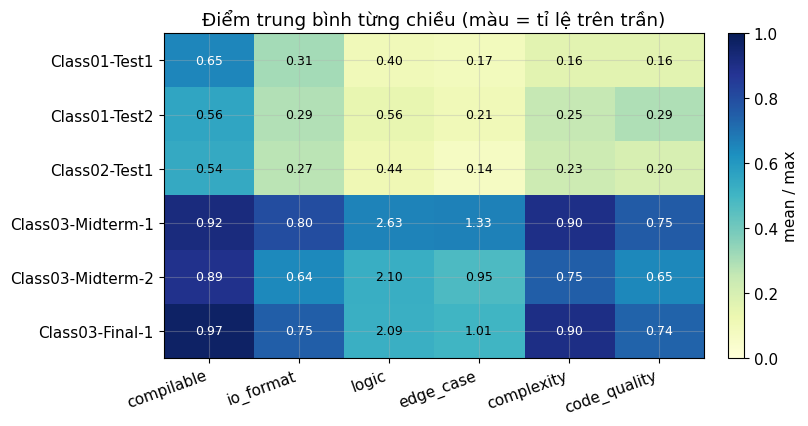

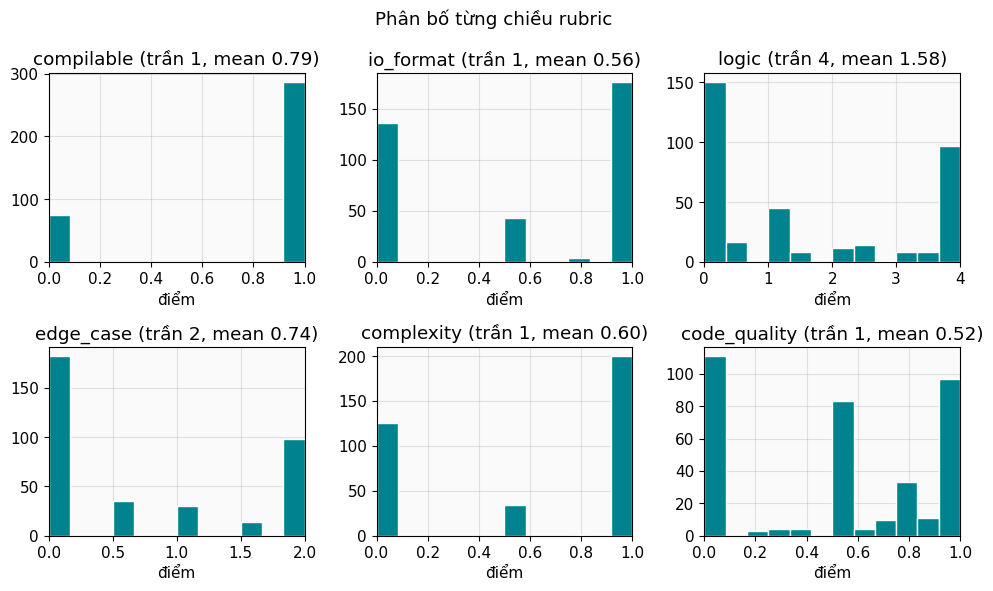

In [5]:
heat = scores.groupby("exam")[DIMENSIONS].mean().reindex(exams)
frac = heat.div(pd.Series(DIM_MAX))
fig, ax = plt.subplots(figsize=(8.2, 4.4))
image = ax.imshow(frac.to_numpy(), vmin=0, vmax=1, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(DIMENSIONS)), DIMENSIONS, rotation=20, ha="right")
ax.set_yticks(range(len(exams)), exams)
for i in range(len(exams)):
    for j, dim in enumerate(DIMENSIONS):
        value = float(frac.iloc[i, j])
        ax.text(j, i, f"{heat.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if value >= 0.62 else "black")
ax.set_title("Điểm trung bình từng chiều (màu = tỉ lệ trên trần)")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="mean / max")
finish(fig, "03_rubric_heatmap")

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, dim in zip(axes.ravel(), DIMENSIONS):
    ceiling = DIM_MAX[dim]
    ax.hist(scores[dim], bins=12, range=(0, ceiling), color="#00838f", edgecolor="white")
    ax.set_xlim(0, ceiling)
    ax.set_title(f"{dim} (trần {ceiling}, mean {scores[dim].mean():.2f})")
    ax.set_xlabel("điểm")
fig.suptitle("Phân bố từng chiều rubric")
finish(fig, "04_dimension_hist")

## 4. Trạng thái từng câu và rule

Trạng thái lấy từ checkpoint, sau khi rule tiên quyết và compile gate đã chạy. Đây là lý do model gán từng câu, không có trong `predictions.json`.

`prereq` / `prereq_zero` là câu tiên quyết làm các câu sau mất điểm. `compile_zero` là bài không biên dịch được nên một số chiều bị đưa về 0.

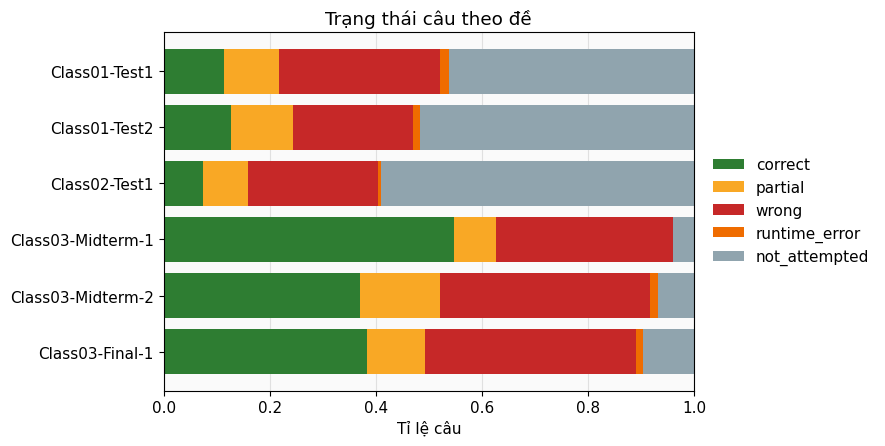

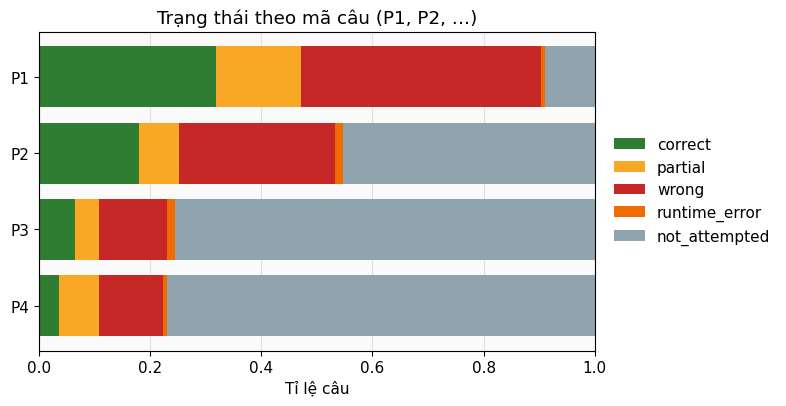

status,correct,partial,wrong,runtime_error,not_attempted
pid,,,,,
P1,115,55,155,3,32
P2,25,10,39,2,63
P3,9,6,17,2,105
P4,5,10,16,1,107


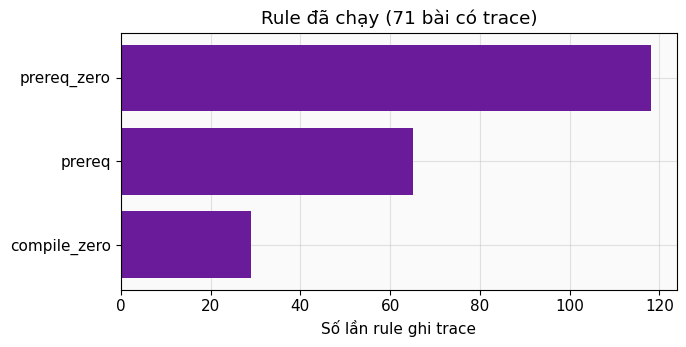

,số lần
kind,
prereq_zero,118
prereq,65
compile_zero,29


In [6]:
if problems.empty:
    print("Không có problems trong checkpoints — bỏ qua biểu đồ trạng thái câu.")
else:
    present = [status for status in STATUSES if status in set(problems["status"])]
    extra = sorted(set(problems["status"]) - set(present))
    status_order = present + extra
    counts = pd.crosstab(problems["exam"], problems["status"]).reindex(index=exams, columns=status_order).fillna(0)
    share = counts.div(counts.sum(axis=1).replace(0, pd.NA), axis=0).fillna(0)
    fig, ax = plt.subplots(figsize=(9, 4.6))
    left = np.zeros(len(share))
    for status in status_order:
        vals = share[status].to_numpy()
        ax.barh(share.index.astype(str), vals, left=left,
                color=STATUS_COLOR.get(status, "#546e7a"), label=status)
        left = left + vals
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_xlabel("Tỉ lệ câu")
    ax.set_title("Trạng thái câu theo đề")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
    finish(fig, "05_status_by_exam")

    by_pid = pd.crosstab(problems["pid"], problems["status"]).reindex(columns=status_order).fillna(0)
    by_pid = by_pid.reindex(sorted(by_pid.index, key=pid_rank))
    share_pid = by_pid.div(by_pid.sum(axis=1).replace(0, pd.NA), axis=0).fillna(0)
    fig, ax = plt.subplots(figsize=(8, 4.2))
    left = np.zeros(len(share_pid))
    for status in status_order:
        vals = share_pid[status].to_numpy()
        ax.barh(share_pid.index.astype(str), vals, left=left,
                color=STATUS_COLOR.get(status, "#546e7a"), label=status)
        left = left + vals
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_xlabel("Tỉ lệ câu")
    ax.set_title("Trạng thái theo mã câu (P1, P2, …)")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
    finish(fig, "06_status_by_problem")
    show(by_pid.astype(int))

if traces.empty:
    print("Không có rule_trace — rule không sửa điểm nào, hoặc checkpoint không ghi trace.")
else:
    kind_counts = traces["kind"].value_counts()
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.barh(kind_counts.index.astype(str)[::-1], kind_counts.to_numpy()[::-1], color="#6a1b9a")
    ax.set_xlabel("Số lần rule ghi trace")
    ax.set_title(f"Rule đã chạy ({traces['sample_id'].nunique()} bài có trace)")
    finish(fig, "07_rule_kinds")
    show(kind_counts.rename("số lần").to_frame())

## 5. Token

Tổng token theo đề tính trên mọi dòng trong `usage.jsonl`, gồm bài chạy lại và lượt smoke nếu còn trong sổ. Đề có prompt dài sẽ nổi lên ở token vào.

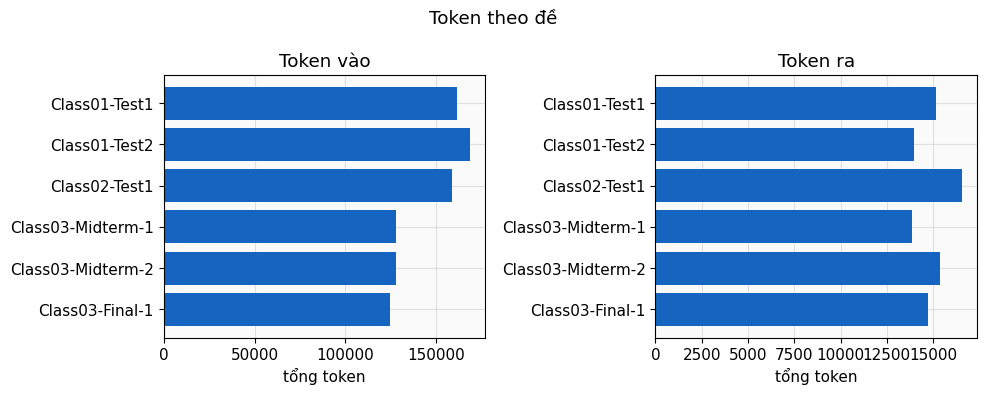

,input_tokens,output_tokens,thinking_tokens
exam,,,
Class01-Test1,161451,15154,0
Class01-Test2,168478,13987,0
Class02-Test1,158731,16542,0
Class03-Midterm-1,127850,13851,0
Class03-Midterm-2,127696,15351,0
Class03-Final-1,124707,14732,0


Tổng sự kiện: 361 | vào 868913 | ra 89617


In [7]:
if usage.empty or "input_tokens" not in usage.columns:
    print("Không có usage.jsonl với token — bỏ qua biểu đồ token.")
else:
    token_cols = [col for col in ("input_tokens", "output_tokens", "thinking_tokens") if col in usage.columns]
    by_token = usage.groupby("exam")[token_cols].sum().reindex(exams).fillna(0)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, col, title in zip(axes, ("input_tokens", "output_tokens"), ("Token vào", "Token ra")):
        if col not in by_token.columns:
            ax.set_visible(False)
            continue
        ax.barh(by_token.index.astype(str), by_token[col], color="#1565c0")
        ax.invert_yaxis()
        ax.set_title(title)
        ax.set_xlabel("tổng token")
    fig.suptitle("Token theo đề")
    finish(fig, "08_tokens_by_exam")
    show(by_token.astype(int))
    print(
        "Tổng sự kiện:", len(usage),
        "| vào", int(usage["input_tokens"].sum()),
        "| ra", int(usage["output_tokens"].sum()) if "output_tokens" in usage else 0,
    )

## 6. Bài nên mở checkpoint

Điểm 0 thường là bài rỗng hoặc không biên dịch được. Các bài điểm thấp còn lại, và bài có `rule_trace`, là chỗ nên mở `checkpoints/<sample_id>.json` để xem trạng thái từng câu.

In [8]:
zeros = scores.loc[scores["total"] == 0, ["sample_id", "exam", "total", *DIMENSIONS]]
lowest = scores.nsmallest(15, "total")[["sample_id", "exam", "total", *DIMENSIONS]]
mismatch = scores.loc[scores["sum_mismatch"], ["sample_id", "total", "rubric_sum"]]
print(f"Điểm 0: {len(zeros)} bài")
if not zeros.empty:
    show(zeros.reset_index(drop=True))
print("15 bài điểm thấp nhất:")
show(lowest.round(2).reset_index(drop=True))
if mismatch.empty:
    print("Mọi total_score khớp tổng sáu chiều.")
else:
    print(f"{len(mismatch)} bài có total_score khác tổng rubric:")
    show(mismatch.round(2))

if not traces.empty:
    touched = (traces.groupby(["sample_id", "exam"]).size()
               .rename("n_trace").reset_index()
               .sort_values("n_trace", ascending=False).head(15))
    print("15 bài bị rule ghi nhiều dòng trace nhất:")
    show(touched.reset_index(drop=True))

if SAVE_REPORT:
    lowest.round(2).to_csv(REPORT_DIR / "low_scores.csv", index=False, encoding="utf-8")
    zeros.to_csv(REPORT_DIR / "zero_scores.csv", index=False, encoding="utf-8")

    def md_table(frame):
        view = frame.reset_index()
        header = "| " + " | ".join(map(str, view.columns)) + " |"
        rule = "| " + " | ".join("---" for _ in view.columns) + " |"
        body = ["| " + " | ".join(str(value) for value in rec) + " |"
                for rec in view.itertuples(index=False)]
        return "\n".join([header, rule, *body])

    parts = [
        "# Báo cáo Task 1 public test",
        "",
        f"- Run: `{RUN_DIR}`",
        f"- {progress.get('provider')} / {progress.get('model')}",
        f"- Tiến độ: {progress.get('completed')}/{progress.get('expected')}",
        f"- File nộp: {progress.get('submission_path') or 'chưa đủ bài'}",
        "",
        "## Điểm theo đề",
        "",
        md_table(by_exam),
        "",
        "Hình: `01_total_hist.png`, `02_total_by_exam.png`, `03_rubric_heatmap.png`, `04_dimension_hist.png`.",
        "",
        "## Bài điểm thấp",
        "",
        md_table(lowest.round(2).set_index("sample_id")),
        "",
    ]
    (REPORT_DIR / "summary.md").write_text("\n".join(parts), encoding="utf-8")
    print("Đã ghi báo cáo vào", REPORT_DIR)

Điểm 0: 64 bài


,sample_id,exam,total,compilable,io_format,logic,edge_case,complexity,code_quality
0,Class01-Test1-S01,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Class01-Test1-S04,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Class01-Test1-S05,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Class01-Test1-S06,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Class01-Test1-S08,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
59,Class03-Midterm-2-S32,Class03-Midterm-2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
60,Class03-Midterm-2-S34,Class03-Midterm-2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
61,Class03-Midterm-2-S56,Class03-Midterm-2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
62,Class03-Final-1-S57,Class03-Final-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0


15 bài điểm thấp nhất:


,sample_id,exam,total,compilable,io_format,logic,edge_case,complexity,code_quality
0,Class01-Test1-S01,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Class01-Test1-S04,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Class01-Test1-S05,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Class01-Test1-S06,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Class01-Test1-S08,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Class01-Test1-S09,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,Class01-Test1-S18,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,Class01-Test1-S20,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,Class01-Test1-S21,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,Class01-Test1-S23,Class01-Test1,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Mọi total_score khớp tổng sáu chiều.
15 bài bị rule ghi nhiều dòng trace nhất:


,sample_id,exam,n_trace
0,Class01-Test1-S35,Class01-Test1,7
1,Class01-Test1-S36,Class01-Test1,7
2,Class01-Test1-S16,Class01-Test1,7
3,Class01-Test2-S11,Class01-Test2,7
4,Class01-Test1-S02,Class01-Test1,6
5,Class01-Test1-S22,Class01-Test1,6
6,Class01-Test1-S34,Class01-Test1,6
7,Class01-Test1-S38,Class01-Test1,6
8,Class02-Test1-S23,Class02-Test1,6
9,Class02-Test1-S25,Class02-Test1,5


Đã ghi báo cáo vào /content/drive/MyDrive/LLM/Final Project/data/outputs/task1/public/gemini/gemini-3.5-flash-lite/e2_zero_shot_structured__gemini__gemini-3.5-flash-lite/891019e6d679/report
